# Task 3

In [961]:
import numpy as np
import pygad
import matplotlib.pyplot as plt
import pandas as pd
import json

In [962]:
def read_txt_to_dict(path):

    # dictionary
    slovar = dict()

    # Open the file
    with open(path, 'r') as file:
        
        for line in file:
            
            # Cleaning the line
            splited = line.replace(",", "").replace("[", "").replace("]", "").replace("\n", "").split(" ")
            
            # Filling dictionary
            slovar[splited[0]] = splited[1:]
            
    return slovar


classes = read_txt_to_dict("Data\\Classes.txt")
classrooms = read_txt_to_dict("Data\\Classrooms.txt")
teachers = read_txt_to_dict("Data\\Teachers.txt")

# Task 3
preferences = dict()
with open("Data\\Preferences.txt", 'r') as file:
    
    for line in file:
        # Splits only by first space
        name, string = line.split(" ", 1)
        string = string.replace("“", '"').replace("”", '"')

        data = json.loads(string)
        preferences[name] = data

# print(preferences["Anna"]["likes"][0])
        

In [963]:
print(classes)
print(classrooms)
print(teachers)
print(preferences)
print()


# Index xy -> x: 0:Programming, 1:Math, 2:Algorithms, 3:OperatingSystems
#          -> y: Which lecture is used

# Predpostavka: Unique classes length is not high
idClasses = []
globalIdClassDictionary = {}
k = 1
slovarTrajanjaUr = {}
for c in classes:
    for i in range(len(classes[c])):
        idClasses.append(k*10 + i)
        slovarTrajanjaUr[k*10+i] = int(classes[c][i])
        # Class name - hourTime - id
        globalIdClassDictionary[k*10 + i] = f"{c}-{k*10 + i} ({classes[c][i]})"
    k+=1
print("idClasses:", idClasses, " -  SlovarTrajanjaUr:", slovarTrajanjaUr)


# Classroom Index: 0:P1, 1:P2, 2:P3, 3:P4
# classroomTime: on index x is start_time and end_time
idClassroom = []
classroomTime = []
n = 0
globalIdClassroomsDictionary = {}

for clas in classrooms:

    c = classrooms[clas]
    classroomTime.append([int(c[0]), int(c[1])])

    globalIdClassroomsDictionary[n] = f"{clas} ({c[0]}-{c[1]})"

    idClassroom.append(n)
    n+=1

print("idClassroom:", idClassroom, " -  classroomTime" ,classroomTime)


# Teacher Index: Anna:0, Brian:1, Charles:2, Diana:3
# teacherClass: on index x are avaible classes that that teacher teachs (ony the first index x)
idTeacher = []
teacherClass = []
globalIdTeachersDictionary = {}
m = 0
for t in teachers:
    idTeacher.append(m)

    globalIdTeachersDictionary[m] = t
    # Which lectures indexed for teachers
    h = []
    for lecture in teachers[t]:
        lec = {"Programming":1, "Math":2, "Algorithms":3, "OperatingSystems":4}

        # Index of a class
        h.append(lec[lecture])

    teacherClass.append(h)
    m+=1


print("idTeacher:", idTeacher, " -  teacherClass:", teacherClass)

print()
print("globalIdClassDictionary", globalIdClassDictionary)
print("globalIdClassroomsDictionary", globalIdClassroomsDictionary)
print("globalIdTeachersDictionary", globalIdTeachersDictionary)

print("_______________________________________________________________________________________")
# From task 3



{'Programming': ['2', '3', '2', '2'], 'Math': ['2', '2'], 'Algorithms': ['2', '3'], 'OperatingSystems': ['2', '2']}
{'P1': ['10', '16'], 'P2': ['8', '16'], 'P3': ['10', '16'], 'P4': ['10', '16']}
{'Anna': ['Programming', 'Math'], 'Brian': ['Programming', 'Algorithms', 'OperatingSystems'], 'Charles': ['Math'], 'Diana': ['Algorithms', 'OperatingSystems']}
{'Anna': {'likes': [10, 11], 'dislikes': [12, 14]}, 'Brian': {'likes': [10, 14], 'dislikes': [15, 16]}, 'Charles': {'likes': [10, 11], 'dislikes': [12, 16]}, 'Diana': {'likes': [10, 14], 'dislikes': [15, 16]}}

idClasses: [10, 11, 12, 13, 20, 21, 30, 31, 40, 41]  -  SlovarTrajanjaUr: {10: 2, 11: 3, 12: 2, 13: 2, 20: 2, 21: 2, 30: 2, 31: 3, 40: 2, 41: 2}
idClassroom: [0, 1, 2, 3]  -  classroomTime [[10, 16], [8, 16], [10, 16], [10, 16]]
idTeacher: [0, 1, 2, 3]  -  teacherClass: [[1, 2], [1, 3, 4], [2], [3, 4]]

globalIdClassDictionary {10: 'Programming-10 (2)', 11: 'Programming-11 (3)', 12: 'Programming-12 (2)', 13: 'Programming-13 (2)',

In [964]:
# From https://pygad.readthedocs.io/en/latest/custom_functions.html
import time

# How quickly does the fitness score increase
fitnessScores = []


# in every call back this will sub to get the time for that callback, 
# and than updated by current time in callback

# Adding time to a dictionary
timeDictionary = {
    "fitness": 0, "parents": 0, "crossover": 0, "mutation": 0, "generation": 0,
    "latest_call_back": 0
}

# When GA starts
def on_start(ga_instance):
    
    # Setting the time when GA starts
    timeDictionary["latest_call_back"] = time.perf_counter()

# When fitness score is calculated
def on_fitness(ga_instance, last_gen_fitness):

    call_back = time.perf_counter()
    # call_back - latest_call_back = time that it took to complete this step!
    # We sum together ans average in the end
    timeDictionary["fitness"] += call_back - timeDictionary["latest_call_back"]
    # Save last callback
    timeDictionary["latest_call_back"] = call_back

# After parents selection
def on_parents(ga_instance, last_gen_parents):
    
    call_back = time.perf_counter()
    timeDictionary["parents"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After crossover is finished
def on_crossover(ga_instance, last_gen_offspring):
    
    call_back = time.perf_counter()
    timeDictionary["crossover"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After mutation
def on_mutation(ga_instance, last_gen_offspring):
        
    call_back = time.perf_counter()
    timeDictionary["mutation"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# At the end of the generation
def on_generation(ga_instance):

    call_back = time.perf_counter()
    timeDictionary["generation"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

    # Best soltion in that generation
    _, fitness, _ = ga_instance.best_solution()

    fitnessScores.append(fitness)

In [965]:
# suitable fitness function that will reward schedules that satisfy the conditions and penalize those that do not.
# (idClass, idClassroom, start, idteacher)
def f(schedule, multiObjectOptimization=False):

    # Global count fitness score
    issue = 0

    # • Every lecture in the classes file must be present in the schedule
    for cid in idClasses:
        find = 0    
        
        # Find if exists 
        for lecture in schedule:
            if lecture[0] == cid: 
                find += 1
            
        # If one lecture/class is not found penatly is high
        if find == 0: 
            issue += 10

        # If some duplicates
        if find > 1:
            issue += 10


    # Every lecture needs to be assigned to a classroom at a time when that classroom is available. 
    # Filled spots (za vsako učilnico toliko pozicij kot ur)
    spots = [ [ 0 for j in range(razred[1]-razred[0])] for razred in classroomTime]
    

    # Teachers hours (end before hour 20)
    teacherSpots = [ [0 for j in range(20)] for _ in idTeacher]

    for lec in schedule:
                
        id_Class, id_Classroom, startHour, id_Teacher = lec
        # You cannot index by float round number
        id_Class, id_Classroom, startHour, id_Teacher = int(id_Class), int(id_Classroom), int(startHour), int(id_Teacher)
    
        # From slovar of hours i get when does this class end 
        endHour = startHour + slovarTrajanjaUr[id_Class]
    
        # What index should it fill (Normalizing so it starts with 0 - for array)
        startIndToFill = startHour - classroomTime[id_Classroom][0]
        endIndToFill = endHour - classroomTime[id_Classroom][0]

        # For how many hours the classroom is open
        dolg = classroomTime[id_Classroom][1] - classroomTime[id_Classroom][0]

        # if the class starts before the classroom opens - penatly (that many hours that is late - increment issue)
        if startHour < classroomTime[id_Classroom][0]:       
            issue += abs(classroomTime[id_Classroom][0] - startHour) * 6
            # The lecture will not be added so +10, because it goes before time 
            # issue += 5
            

        # if class goes longer than the classroom is opne (14-17)=14,15,16 -> thats why -1       
        if endHour > classroomTime[id_Classroom][1]:
            issue += (endHour - classroomTime[id_Classroom][1]) * 6
            # issue += 5
            
        validStart = max(startIndToFill, 0)
        validEnd = min(endIndToFill, dolg)
       
        # Fill the spots and check for overlaping 
        # 10-12 -> increments 10, 11
        for i in range(validStart, validEnd):
            spots[id_Classroom][i]+=1

            # Lectures cannot overlap in the same classroom: a single classroom can hold only a single lecture in a given hour.
            # For every value that is more than 1 -> +1 issue

            # PEnantly if more than 1
            if spots[id_Classroom][i] > 1: issue += 3 * (spots[id_Classroom][i] - 1)

        # Teachers cannot teach more than one lecture at the same time. (So across all the classrooms in a day)
        for i in range(startHour, endHour):
            # If teacher already has a class at that hour
            if teacherSpots[id_Teacher][i] > 0:
                issue += 3
            teacherSpots[id_Teacher][i] += 1


        # Every lecture needs to be assigned a teacher (That teaches that class) 
        # Which classes can the teacher teach
        canTeach = teacherClass[id_Teacher]
        teachingClass = id_Class // 10

        if teachingClass not in canTeach:
            issue+=10


    # So default approach only one function no multiObjects
    if not multiObjectOptimization:

        # SOFT constraints from task 3
        # • Teacher preferences
        # If one of thoose constarints its right i will lower/increase fitness score!
        # I will use teacherSpots from previus solutions
        
        # For each teacher
        teachingHours = []
        for t in idTeacher:

            # get their name
            name = globalIdTeachersDictionary[t]
            # Which time she dis/likes
            likes = preferences[name]["likes"]
            dislikes = preferences[name]["dislikes"]

            # if spots aren't selected they are 0 so no affect
            # If spots she likes are selected (we subtract that amount)
            # [10,11] -> hour 10 is only countzed, [10,14] -> 10,11,12,13
            # 0.1 so (at 0.25 this influenced other problems like overlaping calasses to occour)
            issue -= 0.10 * np.sum(teacherSpots[t][likes[0]:likes[1]])

            # If spots she DISlikes are selected (we increase that amount)
            # * 0.25 to lower the importance (at 0.5 tthis influenced other problems like overlaping calasses to occour)
            issue += 0.25 * np.sum(teacherSpots[t][dislikes[0]:dislikes[1]])





            # • Teacher balance: everyone teaches (approximately) the same number of hours.
            # Number of hours that a t teacher teachs
            num = np.sum(teacherSpots[t])
            teachingHours.append(num)

    
        # Penalizing where teachers are far from average nnumber of teaching hours
        avgTeachingHours = np.mean(teachingHours)

        # For every teacher (teaching Hours)
        for th in teachingHours:

            # a difference between avg and current teaching hours from teacher t
            # Than multiply by 0.25 for each difference
            issue += np.ceil(abs(th - avgTeachingHours)) * 0.25

        
    return issue, teacherSpots

# Negating the value to minimize the fitness_score (in this case error rate)
def fitness_function(ga_instance, solution, x_idx):

    # solution is flat so I had to make it 2D
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]

    score, _ = f(schedule)
    
    return -score

# FOR MULTI OBJECTIVE OPTIMIZATION
def fSoft(teacherSpots):
    
    # SOFT constraints from task 3
    # • Teacher preferences
    # If one of thoose constarints its right i will lower/increase fitness score!
    # I will use teacherSpots from previus solutions
    
    # For each teacher
    teachingHours = []
    issue = 0
    for t in idTeacher:
    
        # get their name
        name = globalIdTeachersDictionary[t]

        # Which time she dis/likes
        likes = preferences[name]["likes"]
        dislikes = preferences[name]["dislikes"]

        # if spots aren't selected they are 0 so no affect
        # If spots she likes are selected (we subtract that amount)
        # [10,11] -> hour 10 is only countzed, [10,14] -> 10,11,12,13
        # 0.1 so (at 0.25 this influenced other problems like overlaping calasses to occour)
        issue -= 0.10 * np.sum(teacherSpots[t][likes[0]:likes[1]])

        # If spots she DISlikes are selected (we increase that amount)
        # * 0.25 to lower the importance (at 0.5 tthis influenced other problems like overlaping calasses to occour)
        issue += 0.25 * np.sum(teacherSpots[t][dislikes[0]:dislikes[1]])
    
    
        # • Teacher balance: everyone teaches (approximately) the same number of hours.
        # Number of hours that a t teacher teachs
        num = np.sum(teacherSpots[t])
        teachingHours.append(num)
    
        
    # Penalizing where teachers are far from average nnumber of teaching hours
    avgTeachingHours = np.mean(teachingHours)
    
    # For every teacher (teaching Hours)
    for th in teachingHours:
    
        # a difference between avg and current teaching hours from teacher t
        # Than multiply by 0.25 for each difference
        issue += np.ceil(abs(th - avgTeachingHours)) * 0.25


    return issue

# multi objective optimization -> so multi fitness function 
def multi_fitness_function(ga_instance, solution, x_idx):
    
    # solution is flat so I had to make it 2D
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]

    scoreHardConst, teacherSpots = f(schedule, multiObjectOptimization=True)
    scoreSoftConts = fSoft(teacherSpots)

    # As in provided link
    # somehow [-53, 0.1] can beat [-6, -0.5], even thought hard constraints are more important so
    # they both beat eachother -53 < -6 and 0.1 > -0.5, so the solution which is closer to zero wins
    # i just hardcoded that scoreHardConst must be 0 for right schedule
    
    # schedule is not good for hard constraints -> penalize with adding to scoreSoftConst
    if scoreHardConst > 0:
        scoreSoftConts = scoreSoftConts + (scoreHardConst)
    

    return [-scoreHardConst, -scoreSoftConts]

In [966]:
import random

# Generating your own initial population. (so generating some valid schedule (or almost valid))
# Better than the GA generated
# I will build valid for first 2 constraint (for teachers it gets more complicated) -> but for teacher who can teach only x class WILL DO
def initialPopulationFunc():

    arrayClasses = np.copy(idClasses)
    # arrayTeachers = np.copy(idTeacher)

    schedule = []
    # startHour: When does class starts, classroomIndex -> which classroom are we in now
    start_Hour = classroomTime[0][0]
    classroomIndex = 0

    # To know how much did we already add lectures
    offsetStartClassroom = [0 for i in range(len(idClassroom))]

    # Adding each class to some avaible classroom (random)
    for _ in arrayClasses:

        # Select a random class
        id_Class = random.choice(arrayClasses)

        # Remove that class from array (to not pick it again)
        arrayClasses = arrayClasses[arrayClasses != id_Class]

        # Get avaible classroom (when can it start) (should all fit -> loop continuesly)
        while start_Hour + slovarTrajanjaUr[id_Class] > classroomTime[classroomIndex][1]:

            # To not over indexed (so in a loop)
            classroomIndex += 1 
            classroomIndex %= len(idClassroom)

            # When the classroom is still free (from what time)
            start_Hour = classroomTime[classroomIndex][0] + offsetStartClassroom[classroomIndex]

            
        # Finding teacher that can teach this class (some variation where can it start)
        canTeach = []
        for i in range(len(teacherClass)):
        
            # If class is avaible to be teached by i teacher
            if (id_Class // 10) in teacherClass[i]:
                canTeach.append(i)
        
        # We select random teacher (i)
        indexOfTeacherThatCanTeach = random.choice(canTeach)

        # Adding to population (idClass, idClassroom, start, idteacher), ectending 1D array
        schedule.extend([id_Class, classroomIndex, start_Hour, indexOfTeacherThatCanTeach])

        # Save to when the class ends (so for another iteration for another class)
        start_Hour += slovarTrajanjaUr[id_Class]
        offsetStartClassroom[classroomIndex] += slovarTrajanjaUr[id_Class]

    # Returning schedule in numpy (faster?)
    return np.array(schedule)



# Using custom crossover operation. (didnt really use constraints here, beside groupin of 4) -> mutation
# parents = num_parents_mating * (idClass, idClassroom, startHour, idTeacher)
# offspring_size = (the offspring size, number of genes)
# ga_instance = From it you can retrieve any proprety
def crossoverFunction(parents, offspring_size, ga_instance):

    # getting Hyper parameter
    num_parents_mating = ga_instance.num_parents_mating
    
    # print(offspring_size.shape) -> (49 -> sol_per_pop, 40 -> 4 genes per 10 parents)
    # print(parents.shape) -> (10 -> parents_mating, 40 -> genes )

    offspring = []
    while len(offspring) != offspring_size[0]:

        # Random id of a parent (0...parent.shape[0]-1)
        idParent1 = random.randint(0, parents.shape[0]-1)
        idParent2 = random.randint(0, parents.shape[0]-1)

        # So the 2 indexes that are selected are different -> not the same parents
        while idParent2 == idParent1:
            idParent2 = random.randint(0, parents.shape[0]-1)

        # 2 solutions as parents - copy to not change original array
        parent1 = np.copy(parents[idParent1])
        parent2 = np.copy(parents[idParent2])

        # every 4 numbers are a one (idClass, idClassroom, startHour, idTeacher) for parent
        numberOfGenes = parents.shape[1] // 4
        crossoverIndex = random.randint(0, numberOfGenes-1) * 4

        # Preforming a crossover (take some from one and then from another one)
        # So not always the same grouping for 2 parents
        if random.randint(0,1) == 0:
            
            parent1[crossoverIndex:] = parent2[crossoverIndex:]
            # appending to new population till length of sol_per_pop
            offspring.append(parent1)
        
        else:

            parent2[crossoverIndex:] = parent1[crossoverIndex:]
            # appending to new population till length of sol_per_pop
            offspring.append(parent2)

       

    # Returns numpy array
    return np.array(offspring)



# Using custom mutation operation -> Most of the constraints into account.
def mutation_func(offspring, ga_instance):

    # Through each solution
    for chromosomeIdx in range(offspring.shape[0]):

        # Calculate schedule so to know how they are ordered???


        # What gene does it change (from (idClass, idClassroom, startHour, idTeacher))
        geneIdx = random.randint(0, offspring.shape[1] - 1)
        parameterIdx = geneIdx % 4


        # id of a class for that lecture where we mutate (to integer so we can index by it)
        id_Class = int(offspring[chromosomeIdx, geneIdx - parameterIdx])
        id_Classroom = int(offspring[chromosomeIdx, geneIdx - parameterIdx + 1])

        # Classes are all already in there from initial population so no need to mutate that

        # Changing idClassroom (swaping with different class)
        if parameterIdx == 1:
            classRoomIdx = random.choice(idClassroom)
            offspring[chromosomeIdx, geneIdx] = classRoomIdx
        
        # Start Hour (+1 -1 if that helps), but cannot be over the limits of classroom
        elif parameterIdx == 2:
            
            startHour = offspring[chromosomeIdx, geneIdx]

            if random.randint(0,1) == 0:
                startHour -= 1

                # Starts before the classroom even opens, it stops and doesnt do anything -> goes into next loop
                if startHour < classroomTime[id_Classroom][0]:
                    continue
            
            else:
                startHour += 1
                endHour = startHour + slovarTrajanjaUr[id_Class]

                # Ends after the classroom closes so not update it
                if endHour > classroomTime[id_Classroom][1]:
                    continue

            # Saving a new value (updating)
            offspring[chromosomeIdx, geneIdx] = startHour


        # idTeacher (just swaping teachers)
        elif parameterIdx == 3:

            # Finding teacher that can teach this class (some variation where can it start)
            canTeach = []
            for i in range(len(teacherClass)):

                # If class is avaible to be teached by i teacher
                if (id_Class // 10) in teacherClass[i]:
                    canTeach.append(i)

            # We select random teacher (i)
            id_Teacher = random.choice(canTeach)
    
            # Changing the teacher for that lecture
            offspring[chromosomeIdx, geneIdx] = id_Teacher
        
        
    
    return offspring


# generatedInitialPopulation = initialPopulationFunc()


In [967]:

# For each diff class id -> have a prebuilt gene space (idClass, idClassroom, start, idteacher)
gene_space = []
for _ in range(len(idClasses)):
    # Extending array further 
    gene_space.extend([
        idClasses,
        idClassroom,
        # start hour, end hour will be calculated in fitness if it fits
        [8, 9, 10, 11, 12, 13, 14, 15],
        idTeacher
    ])
sol_per_pop = 50
# configuring initial population (sol_per_pop)
initialPopulation = np.array( [initialPopulationFunc() for i in range(sol_per_pop)] )

# Genetic Algorithm (sol_per_pop - how many solutions exist in each generation.)
num_gener = 200
ga_instance = pygad.GA(

    fitness_func=multi_fitness_function, 
    # For multi objective optimization
    parent_selection_type="nsga2",

    num_generations=num_gener,
    num_parents_mating=10,
    sol_per_pop=sol_per_pop,
    num_genes = len(gene_space),
    gene_space = gene_space,

    # Custom crossover
    crossover_type = crossoverFunction,

    # Custom mutation 
    mutation_type=mutation_func,  

    # Initial population - made by me
    initial_population=initialPopulation,

    # Same teacher for 2 objects, but different class/hour
    allow_duplicate_genes=True,
    
    # Callbaks
    on_start=on_start,
    on_fitness=on_fitness,
    on_parents=on_parents,
    on_crossover=on_crossover,
    on_mutation=on_mutation,
    on_generation=on_generation,
)

ga_instance.run()
solution, solution_fitness, solution_idx = ga_instance.best_solution()
print("Best parameter", solution)
print("Fitness", solution_fitness)
print("Index", solution_idx)

# # Testing how good is GA in 100 tries
# s = [0,0,0,0,0,0,0,0,0,0,0,0,0,0]
# for i in range(100):
#     s[abs(run())]+=1    
# print(s)

Best parameter [20.  0. 10.  2. 12.  0. 12.  1. 40.  0. 14.  1. 41.  1.  8.  3. 13.  1.
 10.  1. 11.  1. 13.  0. 10.  2. 10.  0. 30.  2. 13.  3. 21.  3. 14.  2.
 31.  3. 10.  3.]
Fitness [ 0.  -1.5]
Index 0


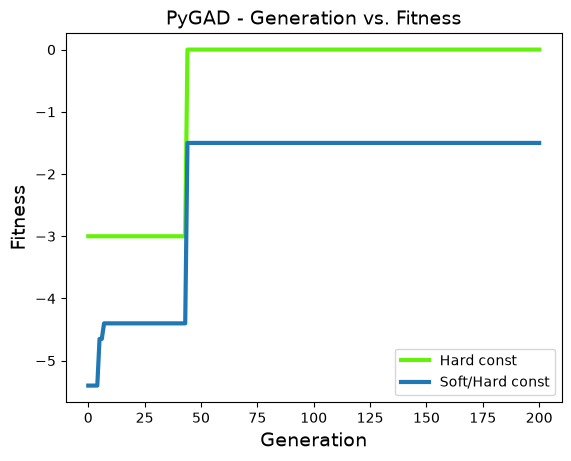

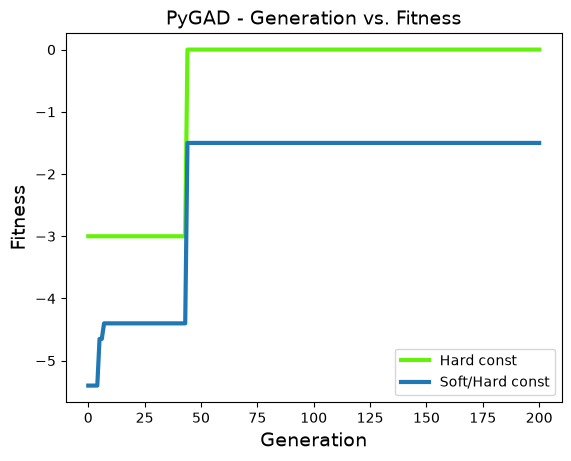

In [968]:
# ga_instance.plot_fitness()
ga_instance.plot_fitness(label=['Hard const', 'Soft/Hard const'])

In [969]:
def display_schedule(schedule):

    # Group lectures by classroom ID
    classrooms = {}
    for lec in schedule:
        
        idClass, idClassroom, startHour, idTeacher = lec
        # You cannot index by float round number
        idClass, idClassroom, startHour, idTeacher = int(idClass), int(idClassroom), int(startHour), int(idTeacher)

        # Saving all hours to a specific classroom - here we didn't yet found it
        if idClassroom not in classrooms:
            classrooms[idClassroom] = []


        classrooms[idClassroom].append((startHour, idClass, idTeacher))


    # Sort classrooms by ID for output
    for idClassroom in sorted(classrooms.keys()):

        # Name
        classroomName = globalIdClassroomsDictionary[idClassroom]
        
        print(f"\n{classroomName}")
        print("-" * 40)
        
        # Sort lectures in this classroom by start hour
        lectures = sorted(classrooms[idClassroom], key=lambda x: x[0])
        
        for start_hour, id_class, id_teacher in lectures:
            
            classsName = globalIdClassDictionary[id_class]
            teachername = globalIdTeachersDictionary[id_teacher]
            endHour = start_hour + slovarTrajanjaUr[id_class]

            # Text Representation
            print(f"  [ {start_hour:02d}:00 - {endHour:02d}:00 ] -> {classsName} (Taught by: {teachername})")
    

# Generated schedule for initial population
# L = [generatedInitialPopulation[i:i+4] for i in range(0, len(generatedInitialPopulation), 4)]
# display_schedule(L)


schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]
display_schedule(schedule)



P1 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Math-20 (2) (Taught by: Charles)
  [ 12:00 - 14:00 ] -> Programming-12 (2) (Taught by: Brian)
  [ 14:00 - 16:00 ] -> OperatingSystems-40 (2) (Taught by: Brian)

P2 (8-16)
----------------------------------------
  [ 08:00 - 10:00 ] -> OperatingSystems-41 (2) (Taught by: Diana)
  [ 10:00 - 12:00 ] -> Programming-13 (2) (Taught by: Brian)
  [ 13:00 - 16:00 ] -> Programming-11 (3) (Taught by: Anna)

P3 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Programming-10 (2) (Taught by: Anna)
  [ 13:00 - 15:00 ] -> Algorithms-30 (2) (Taught by: Diana)

P4 (10-16)
----------------------------------------
  [ 10:00 - 13:00 ] -> Algorithms-31 (3) (Taught by: Diana)
  [ 14:00 - 16:00 ] -> Math-21 (2) (Taught by: Charles)


fitness: 2.6236 s -> avg per step: 13.1178 ms
parents: 4.1695 s -> avg per step: 20.8477 ms
crossover: 0.0442 s -> avg per step: 0.2211 ms
mutation: 0.0142 s -> avg per step: 0.0711 ms
generation: 4.7548 s -> avg per step: 23.7740 ms


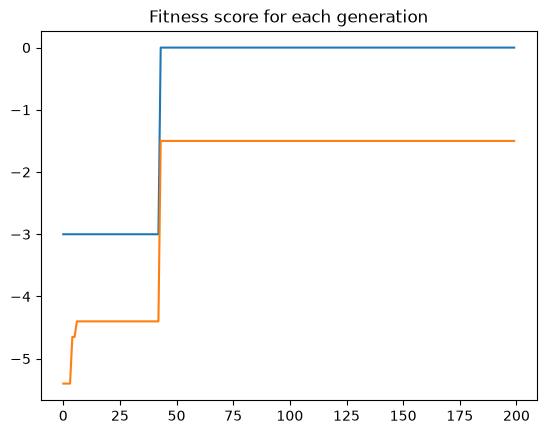

In [970]:
# Time of each step (lifecycle callbacks) <-> Average times
def printTimes():

    allTime = 0
    # For every callback
    for name, value in timeDictionary.items():

        # Ignore latest callback
        if name != "latest_call_back":
            
            # Averaging -> times
            avg = value / num_gener 
            allTime += value
            print(f"{name}: {value:.4f} s -> avg per step: {avg*1000:.4f} ms")

    # Ploting fitnes scores
    # print(fitnessScores)
    plt.plot(np.arange(0, len(fitnessScores)), fitnessScores)
    plt.title("Fitness score for each generation")
    plt.show()



printTimes() 